# Chapter 11: Complete, Run, and Train Your First Deep Neural Network

## Learning Objectives

This chapter combines forward propagation, error calculation, and weight updates into a small neural network.

The main objectives are:
1. Implement a neural network using NumPy.
2. Calculate predictions using forward propagation.
3. Calculate gradients and update weights.
4. Observe how training changes the model's predictions.

## 1. Neural Network Architecture

A neural network consists of interconnected computational units called neurons.

Each neuron calculates a weighted combination of its inputs. During training, the network adjusts its weights to reduce the difference between its predictions and the target values.

A basic training workflow includes:

1. Initialize weights.
2. Perform forward propagation.
3. Calculate the loss.
4. Calculate gradients.
5. Update weights.
6. Repeat for multiple training iterations.

This notebook uses a small network with one input, one hidden layer, and one output.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Toy dataset: one input feature and one target
X = np.array([[0.0], [1.0], [2.0], [3.0]])

y = np.array([[0.0], [0.3], [0.6], [0.9]])

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (4, 1)
Target shape: (4, 1)


In [2]:
np.random.seed(42)

input_size = 1
hidden_size = 4
output_size = 1

# Weights between input and hidden layer
W1 = np.random.randn(input_size, hidden_size) * 0.1

# Bias for hidden layer
b1 = np.zeros((1, hidden_size))

# Weights between hidden and output layer
W2 = np.random.randn(hidden_size, output_size) * 0.1

# Bias for output layer
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (1, 4)
b1 shape: (1, 4)
W2 shape: (4, 1)
b2 shape: (1, 1)


In [3]:
def forward_pass(X, W1, b1, W2, b2):
    # Hidden layer: linear transformation
    hidden_linear = np.dot(X, W1) + b1

    # ReLU activation
    hidden_activation = np.maximum(0, hidden_linear)

    # Output layer: linear prediction
    output = np.dot(hidden_activation, W2) + b2

    return hidden_linear, hidden_activation, output


hidden_linear, hidden_activation, predictions = forward_pass(
    X, W1, b1, W2, b2
)

print("Predictions before training:")
print(predictions)

Predictions before training:
[[0.        ]
 [0.02075357]
 [0.04150713]
 [0.0622607 ]]


## 2. Forward Propagation

Forward propagation passes input data through the network to produce predictions.

The hidden layer first calculates:

Z1 = XW1 + b1

The ReLU activation function is then applied:

A1 = max(0, Z1)

The output layer calculates:

Prediction = A1W2 + b2

The hidden layer allows the model to learn intermediate representations. The ReLU activation introduces nonlinearity, allowing the network to represent relationships beyond a simple linear transformation.

In [4]:
learning_rate = 0.01
epochs = 5000

loss_history = []
n_samples = X.shape[0]

for epoch in range(epochs):
    # Forward propagation
    Z1, A1, predictions = forward_pass(X, W1, b1, W2, b2)

    # Mean squared error
    error = predictions - y
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Gradient at output layer
    d_output = (2 / n_samples) * error

    dW2 = np.dot(A1.T, d_output)
    db2 = np.sum(d_output, axis=0, keepdims=True)

    # Backpropagate through W2
    dA1 = np.dot(d_output, W2.T)

    # Derivative of ReLU
    dZ1 = dA1 * (Z1 > 0)

    dW1 = np.dot(X.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Update weights and biases
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

print("Final loss:", loss_history[-1])

Final loss: 1.2442168347856437e-09


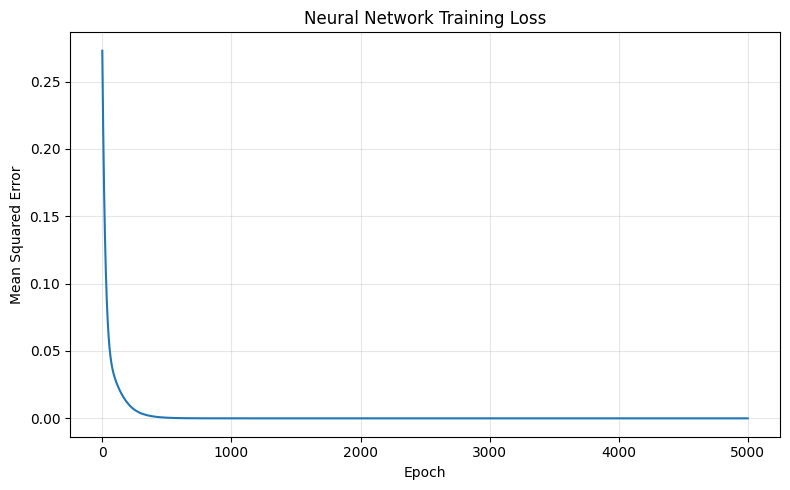

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Neural Network Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
_, _, final_predictions = forward_pass(X, W1, b1, W2, b2)

results = np.column_stack(
    (X.flatten(), y.flatten(), final_predictions.flatten())
)

print("Input | Target | Prediction")
print(results)

Input | Target | Prediction
[[0.00000000e+00 0.00000000e+00 3.93094845e-05]
 [1.00000000e+00 3.00000000e-01 2.99949301e-01]
 [2.00000000e+00 6.00000000e-01 5.99988002e-01]
 [3.00000000e+00 9.00000000e-01 9.00026703e-01]]


## Conclusion

This chapter combines forward propagation, loss calculation, backpropagation, and gradient descent into a trainable neural network.

The hidden layer transforms input data into an intermediate representation, while the output layer generates predictions. Backpropagation calculates gradients, and gradient descent updates the model parameters.

The training loss helps indicate whether the model is improving. However, a low training loss alone does not guarantee good performance on unseen data.